# 03. Model A: Logistic Regression

**Owner:** Member A (Logistic Regression)
**Step 10:** tune the Logistic Regression on the training years, choose its decision threshold, and check it once on the validation years.

**Inputs.** The agreed preprocessing from step 8, `make_selected_preprocessor()`: the shared pipeline followed by L1 selection, which keeps 9 of the 42 encoded inputs. Every input is standardised, and the case and rainfall counts are log-transformed first.

**The bar to beat** (from `03_baselines.ipynb`): the persistence score, which ranks weeks by this week's cases divided by the district's outbreak threshold. It reaches PR-AUC **0.687** across the 2016 to 2020 cross-validation years and **0.554** on 2021 to 2022, without any learning.

**Rules this notebook follows** (the same as `03_model_b_random_forest.ipynb`)

- Hyperparameters are chosen on the five expanding-window cross-validation years (2016 to 2020) only.
- The decision threshold is chosen on the same cross-validation predictions.
- The validation years 2021 to 2022 are used once, at the end, as a check. Nothing is changed after seeing them.
- The test years 2023 to 2025 stay sealed until step 11.

## 1. How Logistic Regression works, and why it suits this problem

*Notes for the report's algorithm section (criterion 4).*

**The model.** Logistic Regression is a parametric, model-based classifier (lecture 4). It learns one weight θ per input and combines them into a linear score, z = θ₀ + θ₁x₁ + ... + θₙxₙ. The sigmoid function, σ(z) = 1 / (1 + e⁻ᶻ), turns that score into a probability between 0 and 1. The score z is the log-odds of an outbreak, so each weight says how much one unit of its input shifts the log-odds. The decision boundary, where the probability crosses the chosen threshold, is a straight line (a hyperplane) in the space of the inputs.

**Training.** The weights are found by minimising log loss (cross-entropy), which heavily penalises confident wrong predictions. Log loss is convex for Logistic Regression, so there is a single best set of weights and no dependence on random starting points.

**Regularisation.** An L2 (ridge) penalty on the size of the weights is added to the log loss (lecture 3). It shrinks all weights towards zero without setting any to exactly zero. Its strength is set by C: a small C means strong shrinkage and a simpler model; a large C lets the weights fit the training years more closely. L2 matters here because several inputs are strongly correlated (this week's cases, last week's cases and cases relative to the threshold), which on their own would make the individual weights unstable.

**Why it suits this problem**

- It outputs a probability of an outbreak, which is what a public-health team would act on.
- Because every input is standardised, each weight is the change in log-odds for a one standard deviation rise in that input, and e^θ is the corresponding odds ratio. The model can be read and explained directly.
- Outbreak risk rises steadily with the case level, and the log transform in the preprocessing turns that into a near-linear relationship the model can capture.
- It has a single main hyperparameter, trains in seconds, and behaves stably on correlated inputs once regularised.

**Weaknesses to keep in mind**

- The log-odds are linear in the inputs, so the model cannot represent thresholds or interactions (for example, rainfall mattering only when cases are already high) unless such features are built by hand. A Random Forest finds them on its own.
- Correlated inputs share credit between them, so individual weights should be read with care even with regularisation.

**Hyperparameters tuned here**

| Hyperparameter | What it controls | Values tried |
|---|---|---|
| `C` | Inverse strength of the L2 penalty | 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10 |
| `class_weight` | Whether outbreak weeks are up-weighted | none, balanced |

In [1]:
import json
import sys
import time
from pathlib import Path

# Make the project root importable so the shared `src` modules work from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

from src import config, viz
from src.evaluation import (
    METRIC_NAMES, choose_threshold, classification_metrics, cross_validate, out_of_fold_scores,
    reference_models,
)
from src.preprocessing import (
    CV_VALIDATION_YEARS, MODEL_FEATURES, build_model_frame, expanding_year_folds,
    make_selected_preprocessor, selected_inputs,
)

viz.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
frame = build_model_frame()
train_frame = frame[frame["split"] == "train"].reset_index(drop=True)
val_frame = frame[frame["split"] == "val"].reset_index(drop=True)
X, y = train_frame[MODEL_FEATURES], train_frame["target"]
X_val, y_val = val_frame[MODEL_FEATURES], val_frame["target"]
folds = expanding_year_folds(train_frame)
YEARS = [str(year) for year in CV_VALIDATION_YEARS]

# The bar from step 9: PR-AUC of the persistence score in each cross-validation year.
persistence_score_cv = pd.Series(
    [average_precision_score(y.iloc[va], train_frame["cases_rel_threshold"].iloc[va]) for _, va in folds],
    index=YEARS,
)
PERSISTENCE_SCORE_CV = persistence_score_cv.mean()
print(f"Training rows: {len(X):,}   Validation rows (2021-2022): {len(X_val):,}")
print(f"Persistence score, mean PR-AUC across 2016-2020: {PERSISTENCE_SCORE_CV:.3f}")

Training rows: 18,200   Validation rows (2021-2022): 2,575
Persistence score, mean PR-AUC across 2016-2020: 0.687


## 2. Tuning with grid search

Every combination in the grid is scored on the same five expanding-window folds used throughout the project: for each validation year, the model is trained on all earlier years and scored on that year by PR-AUC. The combination with the highest mean PR-AUC across the five years wins.

The grid has 9 × 2 = 18 combinations, so the search fits 90 models. It takes a few seconds.

In [3]:
GRID = {
    "clf__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    "clf__class_weight": [None, "balanced"],
}
pipeline = Pipeline([
    ("prep", make_selected_preprocessor()),
    ("clf", LogisticRegression(max_iter=5000)),  # L2 penalty, the scikit-learn default
])
search = GridSearchCV(pipeline, GRID, cv=folds, scoring="average_precision", n_jobs=-1, refit=True)

start = time.time()
search.fit(X, y)
print(f"Fitted {len(search.cv_results_['params']) * len(folds)} models in {(time.time() - start) / 60:.1f} minutes.")
print("Best settings:", {k.replace("clf__", ""): v for k, v in search.best_params_.items()})
print(f"Best mean PR-AUC across 2016-2020: {search.best_score_:.3f}")

Fitted 90 models in 0.1 minutes.
Best settings: {'C': 10, 'class_weight': None}
Best mean PR-AUC across 2016-2020: 0.696


In [4]:
PARAM_LABELS = {"clf__C": "C", "clf__class_weight": "class_weight"}
cv_table = pd.DataFrame(search.cv_results_)
# Labels come from the raw parameter dicts, so None (no class weighting) stays visible.
tuning = pd.DataFrame({label: [str(p[param]) for p in search.cv_results_["params"]]
                       for param, label in PARAM_LABELS.items()})
tuning["mean PR-AUC"] = cv_table["mean_test_score"]
tuning["std across years"] = cv_table["std_test_score"]
for i, year in enumerate(YEARS):
    tuning[year] = cv_table[f"split{i}_test_score"]
tuning["rank"] = cv_table["rank_test_score"]
tuning = tuning.iloc[np.argsort(cv_table["rank_test_score"].to_numpy(), kind="stable")].reset_index(drop=True)
assert search.best_score_ == tuning.loc[0, "mean PR-AUC"]  # row 0 is the winning combination
tuning.head(10)

,C,class_weight,mean PR-AUC,std across years,2016,2017,2018,2019,2020,rank
0,10,None,0.696,0.244,0.269,0.882,0.580,0.917,0.833,1
1,0.03,None,0.696,0.243,0.274,0.887,0.575,0.915,0.829,2
2,3,None,0.696,0.245,0.268,0.882,0.580,0.917,0.833,3
3,1,None,0.696,0.245,0.268,0.882,0.580,0.917,0.833,4
4,0.3,None,0.696,0.245,0.267,0.883,0.579,0.917,0.832,5
5,0.01,None,0.695,0.241,0.280,0.890,0.569,0.914,0.822,6
6,0.1,None,0.695,0.247,0.263,0.884,0.578,0.917,0.832,7
7,0.3,balanced,0.693,0.241,0.273,0.881,0.574,0.913,0.822,8
8,10,balanced,0.693,0.241,0.274,0.881,0.574,0.913,0.821,9
9,0.1,balanced,0.693,0.241,0.273,0.881,0.573,0.913,0.822,10


### 2.1 What each setting does

Mean cross-validation PR-AUC for every value of C, with and without class weighting. The dashed line is the persistence score.

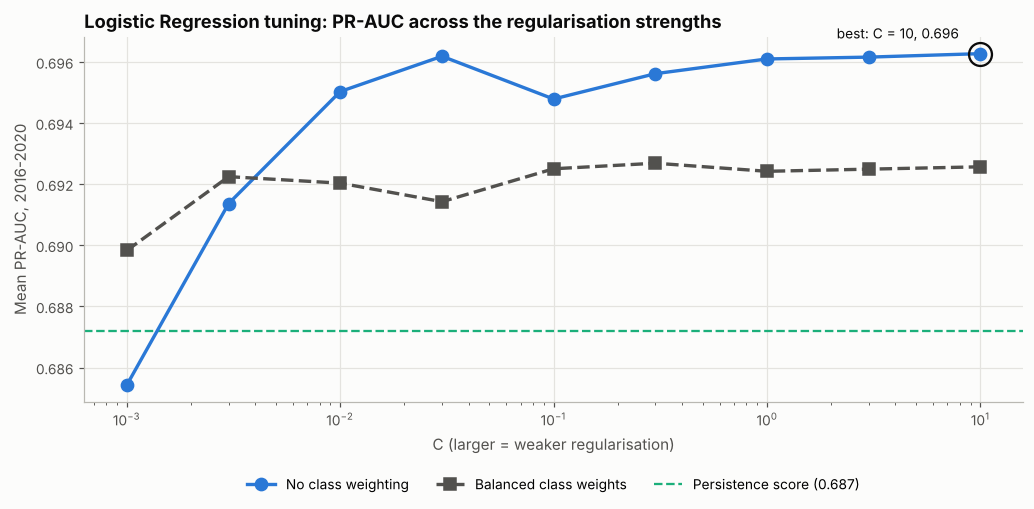

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for weight, colour, style, marker, label in [
    ("None", viz.BLUE, "-", "o", "No class weighting"),
    ("balanced", viz.TEXT_MUTED, "--", "s", "Balanced class weights"),
]:
    part = tuning[tuning["class_weight"] == weight].assign(C=lambda d: d["C"].astype(float)).sort_values("C")
    ax.plot(part["C"], part["mean PR-AUC"], color=colour, linestyle=style, marker=marker, markersize=8,
            linewidth=2.2, label=label, zorder=3)
best = tuning.loc[0]
ax.plot(float(best["C"]), best["mean PR-AUC"], "o", markersize=15, markerfacecolor="none",
        markeredgecolor=viz.TEXT, markeredgewidth=1.5, zorder=4)
ax.annotate(f"best: C = {best['C']}, {best['mean PR-AUC']:.3f}", (float(best["C"]), best["mean PR-AUC"]),
            textcoords="offset points", xytext=(-14, 10), ha="right", fontsize=9, color=viz.TEXT)
ax.axhline(PERSISTENCE_SCORE_CV, color=viz.AQUA, linestyle="--", linewidth=1.5, zorder=1,
           label=f"Persistence score ({PERSISTENCE_SCORE_CV:.3f})")
ax.set_xscale("log")
ax.set_xlabel("C (larger = weaker regularisation)")
ax.set_ylabel("Mean PR-AUC, 2016-2020")
ax.set_title("Logistic Regression tuning: PR-AUC across the regularisation strengths")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
fig.tight_layout()
viz.save(fig, "lr_01_tuning")
plt.show()

**Finding.** Regularisation strength barely matters. Without class weighting, every C from 0.01 to 10 scores between 0.695 and 0.696; only very strong regularisation pulls the score down, to 0.685 at C = 0.001, just below the persistence score. With 18,200 training weeks and only 9 inputs there is far more data than parameters, so the weights are well determined and the L2 penalty has little to correct. The winning setting, C = 10, is close to no regularisation at all, and C = 0.03 scores the same to three decimals.

As with the Random Forest, class weighting does not help: the best balanced setting reaches 0.693. Up-weighting outbreak weeks mainly shifts the intercept, raising every predicted probability, and changes their order only slightly. PR-AUC measures the order, and the class imbalance is handled by the decision threshold instead.

## 3. Tuned model against the bar, year by year

The untuned model is the step 8 reference Logistic Regression (C = 1 with balanced class weights) on the same 9 inputs.

In [6]:
untuned = cross_validate(make_selected_preprocessor, X, y, folds,
                         models={"Logistic Regression": reference_models()["Logistic Regression"]})
by_year = pd.DataFrame({
    "Persistence score": persistence_score_cv,
    "Logistic Regression, untuned (step 8)": untuned["pr_auc"].to_numpy(),
    "Logistic Regression, tuned": tuning.loc[0, YEARS].astype(float).to_numpy(),
}, index=YEARS).T
by_year["mean"] = by_year.mean(axis=1)
by_year.loc["Tuned minus persistence score"] = by_year.loc["Logistic Regression, tuned"] - by_year.loc["Persistence score"]
by_year

,2016,2017,2018,2019,2020,mean
Persistence score,0.291,0.890,0.544,0.916,0.796,0.687
"Logistic Regression, untuned (step 8)",0.274,0.881,0.574,0.913,0.821,0.692
"Logistic Regression, tuned",0.269,0.882,0.580,0.917,0.833,0.696
Tuned minus persistence score,-0.023,-0.008,0.037,0.002,0.037,0.009


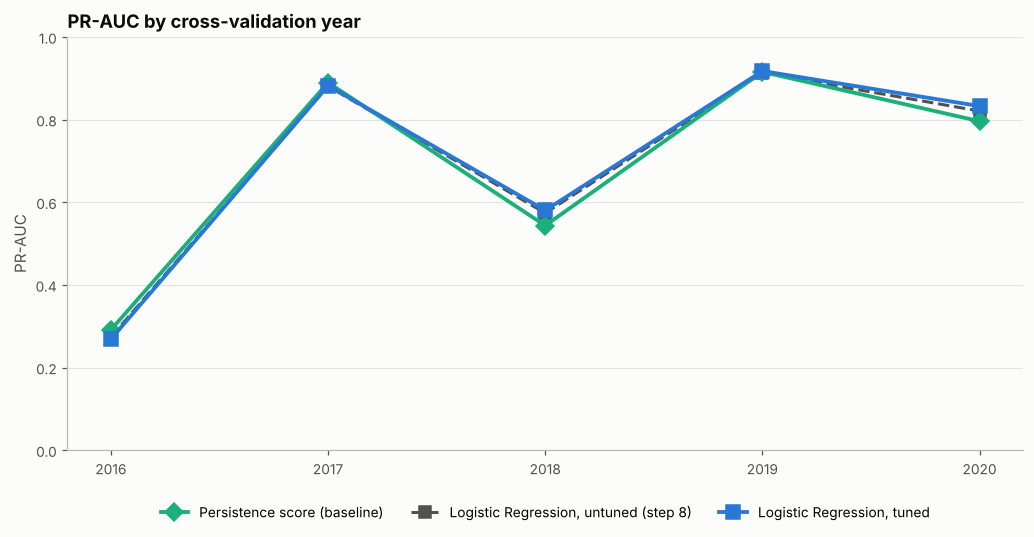

In [7]:
x = np.arange(len(YEARS))
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.plot(x, by_year.loc["Persistence score", YEARS], color=viz.AQUA, linewidth=2.5, marker="D", markersize=8,
        label="Persistence score (baseline)", zorder=3)
ax.plot(x, by_year.loc["Logistic Regression, untuned (step 8)", YEARS], color=viz.TEXT_MUTED, linestyle="--",
        linewidth=2, marker="s", markersize=8, label="Logistic Regression, untuned (step 8)", zorder=2)
ax.plot(x, by_year.loc["Logistic Regression, tuned", YEARS], color=viz.BLUE, linewidth=2.5, marker="s",
        markersize=9, label="Logistic Regression, tuned", zorder=4)
ax.set_xticks(x, YEARS)
ax.set_ylim(0, 1)
ax.set_ylabel("PR-AUC")
ax.set_title("PR-AUC by cross-validation year")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
fig.tight_layout()
viz.save(fig, "lr_02_cv_by_year")
plt.show()

**Finding.** The tuned model edges past the persistence score on average, 0.696 against 0.687 (+0.009), but not in every year. It is ahead in 2018 (+0.037) and 2020 (+0.037), level in 2019 (+0.002), and behind in 2016 (-0.023) and 2017 (-0.008). Tuning adds only 0.004 over the untuned step 8 model, because that model (C = 1 with balanced weights) already sat on the same flat plateau.

## 4. Choosing the decision threshold

PR-AUC judges the ranking. To issue an actual warning, the model needs a cut-off: predict an outbreak when its probability is at or above the threshold.

The threshold is chosen exactly as for the Random Forest: on the cross-validation predictions, where each year 2016 to 2020 is scored by a model trained only on earlier years (`out_of_fold_scores`), picking the threshold that maximises F1 averaged across the five years (`choose_threshold`), so each year counts equally.

In [8]:
final_pipeline = clone(search.best_estimator_)
oof = out_of_fold_scores(final_pipeline, X, y, folds)
oof["target"] = y.iloc[oof.index].to_numpy()
oof["outbreak_now"] = train_frame["outbreak_now"].iloc[oof.index].to_numpy()
oof["persistence score"] = train_frame["cases_rel_threshold"].iloc[oof.index].to_numpy()

# The out-of-fold scores must reproduce the grid search's fold scores exactly.
oof_pr_auc = [average_precision_score(g["target"], g["score"]) for _, g in oof.groupby("fold")]
assert np.allclose(oof_pr_auc, tuning.loc[0, YEARS].astype(float).to_numpy())

THRESHOLD = choose_threshold(oof["target"], oof["score"], groups=oof["fold"])
print(f"Chosen threshold: {THRESHOLD:.3f}")

Chosen threshold: 0.242


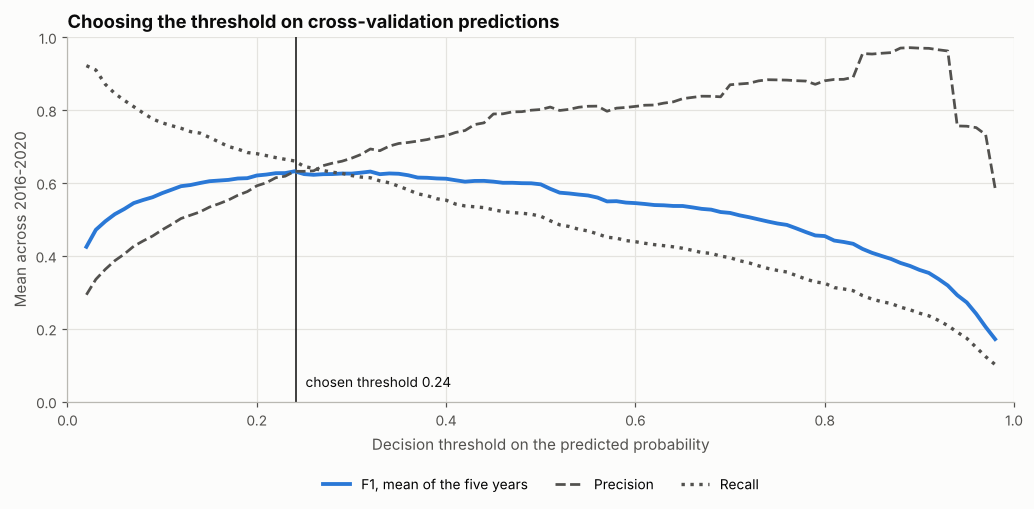

In [9]:
grid = np.round(np.arange(0.02, 0.99, 0.01), 2)
curves = {name: [] for name in ("precision", "recall", "F1")}
for t in grid:
    per_year = [classification_metrics(g["target"], g["score"], t) for _, g in oof.groupby("fold")]
    for name in curves:
        curves[name].append(np.mean([m[name] for m in per_year]))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(grid, curves["F1"], color=viz.BLUE, linewidth=2.5, label="F1, mean of the five years")
ax.plot(grid, curves["precision"], color=viz.TEXT_MUTED, linestyle="--", linewidth=1.8, label="Precision")
ax.plot(grid, curves["recall"], color=viz.TEXT_MUTED, linestyle=":", linewidth=2.2, label="Recall")
ax.axvline(THRESHOLD, color=viz.TEXT, linewidth=1, zorder=1)
ax.annotate(f"chosen threshold {THRESHOLD:.2f}", (THRESHOLD, 0.04), textcoords="offset points", xytext=(6, 0),
            fontsize=9, color=viz.TEXT)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Decision threshold on the predicted probability")
ax.set_ylabel("Mean across 2016-2020")
ax.set_title("Choosing the threshold on cross-validation predictions")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
fig.tight_layout()
viz.save(fig, "lr_03_threshold")
plt.show()

In [10]:
SUMMARY_METRICS = ["PR-AUC", "ROC-AUC", "precision", "recall", "F1", "MCC", "accuracy"]
rows = []
for year, g in zip(YEARS, (g for _, g in oof.groupby("fold"))):
    rows.append({"model": "Logistic Regression, tuned", "year": year,
                 **classification_metrics(g["target"], g["score"], THRESHOLD)})
    rows.append({"model": "Persistence", "year": year, **classification_metrics(g["target"], g["outbreak_now"], 0.5)})
cv_metrics = pd.DataFrame(rows)
cv_metrics_mean = cv_metrics.groupby("model", sort=False)[SUMMARY_METRICS].mean()
cv_metrics_mean

,PR-AUC,ROC-AUC,precision,recall,F1,MCC,accuracy
model,,,,,,,
"Logistic Regression, tuned",0.696,0.899,0.632,0.660,0.632,0.568,0.904
Persistence,0.496,0.796,0.624,0.664,0.638,0.568,0.906


**Finding.** The chosen threshold is 0.24. Without class weighting, the model's probabilities stay close to the true outbreak rate of about 8%, so the cut-off that best balances precision and recall sits well below one half. At this cut-off its yes or no warnings across 2016 to 2020 match those of persistence almost exactly: precision 0.632 against 0.624, recall 0.660 against 0.664, F1 0.632 against 0.638, and MCC 0.568 for both.

As for the Random Forest, the model's advantage lies in its ranking (PR-AUC 0.696 against 0.496 for the 0 or 1 persistence rule), which matters as soon as the cut-off has to move.

## 5. Where the gain comes from: onsets and continuing outbreaks

Every week falls into one of two situations, and they pose different questions:

- **No outbreak now.** Will one start within two weeks? These onset weeks are where an early warning is most useful, and the hardest to predict. Plain persistence misses all of them by definition.
- **Outbreak now.** Will it still be running in two weeks, or will it have ended?

The table scores the model and the persistence score separately within each situation, in each cross-validation year. In the onset columns, chance level is the onset rate.

In [11]:
rows = []
for year, g in zip(YEARS, (g for _, g in oof.groupby("fold"))):
    calm, active = g[g["outbreak_now"] == 0], g[g["outbreak_now"] == 1]
    rows.append({
        "year": year,
        "onsets": int(calm["target"].sum()),
        "onset rate": calm["target"].mean(),
        "onsets: LR PR-AUC": average_precision_score(calm["target"], calm["score"]),
        "onsets: persistence score PR-AUC": average_precision_score(calm["target"], calm["persistence score"]),
        "onsets: LR recall at threshold": classification_metrics(calm["target"], calm["score"], THRESHOLD)["recall"],
        "continuing: LR PR-AUC": average_precision_score(active["target"], active["score"]),
        "continuing: persistence score PR-AUC": average_precision_score(active["target"], active["persistence score"]),
    })
onsets = pd.DataFrame(rows).set_index("year")
onsets.loc["mean"] = onsets.mean()
onsets.loc["mean", "onsets"] = np.nan
onsets["onsets"] = onsets["onsets"].astype("Int64")
onsets

,onsets,onset rate,onsets: LR PR-AUC,onsets: persistence score PR-AUC,onsets: LR recall at threshold,continuing: LR PR-AUC,continuing: persistence score PR-AUC
year,,,,,,,
2016,43,0.034,0.129,0.185,0.070,0.573,0.581
2017,139,0.217,0.428,0.396,0.223,0.935,0.940
2018,42,0.036,0.090,0.119,0.119,0.814,0.743
2019,72,0.074,0.391,0.362,0.181,0.972,0.968
2020,10,0.009,0.246,0.094,0.300,0.885,0.858
mean,<NA>,0.074,0.257,0.231,0.178,0.836,0.818


**Finding.** Logistic Regression ranks onsets better than the persistence score: mean PR-AUC 0.257 against 0.231, about three and a half times chance (0.074). It is ahead in 2017, 2019 and 2020 and behind in 2016 and 2018. 2020 holds only 10 onsets, so the large margin there is fragile. At the chosen threshold the model flags 18% of onsets, against 6% for the Random Forest (`03_model_b_random_forest.ipynb`).

On weeks already in outbreak it is also ahead (0.836 against 0.818), with the largest margin in 2018 (0.814 against 0.743).

## 6. One check on the validation years, 2021 to 2022

The tuned model is trained on all training years (2007 to 2020) with the chosen settings, then scored once on 2021 to 2022 at the threshold chosen above. The untuned step 8 model and both persistence baselines are shown for reference. Nothing in this notebook is changed after this point.

In [12]:
final_model = search.best_estimator_  # refitted on all of 2007-2020 by GridSearchCV
untuned_model = Pipeline([("prep", make_selected_preprocessor()),
                          ("clf", reference_models()["Logistic Regression"])]).fit(X, y)

validation = pd.DataFrame({
    "Logistic Regression, tuned": classification_metrics(y_val, final_model.predict_proba(X_val)[:, 1], THRESHOLD),
    "Logistic Regression, untuned (step 8)": classification_metrics(y_val, untuned_model.predict_proba(X_val)[:, 1], 0.5),
    "Persistence score": classification_metrics(y_val, val_frame["cases_rel_threshold"], 1.0),
    "Persistence": classification_metrics(y_val, val_frame["outbreak_now"], 0.5),
}).T[METRIC_NAMES]

calm = (val_frame["outbreak_now"] == 0).to_numpy()
validation["onset PR-AUC"] = [
    average_precision_score(y_val[calm], final_model.predict_proba(X_val[calm])[:, 1]),
    average_precision_score(y_val[calm], untuned_model.predict_proba(X_val[calm])[:, 1]),
    average_precision_score(y_val[calm], val_frame.loc[calm, "cases_rel_threshold"]),
    float(y_val[calm].mean()),
]
validation[["TP", "FP", "FN", "TN"]] = validation[["TP", "FP", "FN", "TN"]].astype(int)
validation

,PR-AUC,ROC-AUC,precision,recall,F1,MCC,accuracy,TP,FP,FN,TN,onset PR-AUC
"Logistic Regression, tuned",0.585,0.951,0.500,0.584,0.539,0.525,0.970,45,45,32,2453,0.173
"Logistic Regression, untuned (step 8)",0.582,0.955,0.272,0.818,0.408,0.446,0.929,63,169,14,2329,0.149
Persistence score,0.554,0.933,0.558,0.558,0.558,0.545,0.974,43,34,34,2464,0.082
Persistence,0.325,0.772,0.558,0.558,0.558,0.545,0.974,43,34,34,2464,0.014


**Finding.** On 2021 to 2022 the tuned model scores PR-AUC 0.585, ahead of the persistence score (0.554) and of the Random Forest (0.538). At its threshold it catches 45 of the 77 outbreaks, two more than persistence, with 45 false alarms against 34, so its F1 (0.539) and MCC (0.525) are slightly below persistence's (0.558 and 0.545). It ranks onsets clearly better than the persistence score: 0.173 against 0.082, with chance at 0.014.

The untuned step 8 model ranks almost as well (0.582), but its threshold of 0.5 on class-weighted probabilities raises 169 false alarms to catch 63 outbreaks. That is why the threshold has to be chosen rather than left at 0.5.

### 6.1 Is the gap on 2021 to 2022 larger than chance variation?

The two years hold only 77 outbreak weeks, so a handful of weeks can move PR-AUC noticeably. As for the Random Forest, the difference in PR-AUC between the tuned model and the persistence score is recomputed on 2,000 bootstrap resamples of whole districts.

In [13]:
lr_val = final_model.predict_proba(X_val)[:, 1]
ps_val = val_frame["cases_rel_threshold"].to_numpy()
y_val_array = y_val.to_numpy()
district_rows = [np.flatnonzero(val_frame[config.DISTRICT_COL].to_numpy() == d)
                 for d in val_frame[config.DISTRICT_COL].unique()]

rng = np.random.default_rng(config.RANDOM_SEED)
differences = []
for _ in range(2000):
    picked = rng.integers(0, len(district_rows), len(district_rows))
    idx = np.concatenate([district_rows[i] for i in picked])
    if y_val_array[idx].sum() == 0:
        continue
    differences.append(average_precision_score(y_val_array[idx], lr_val[idx])
                       - average_precision_score(y_val_array[idx], ps_val[idx]))
differences = np.array(differences)
observed = average_precision_score(y_val_array, lr_val) - average_precision_score(y_val_array, ps_val)
low, high = np.percentile(differences, [2.5, 97.5])
print(f"Observed difference (tuned model minus persistence score): {observed:+.3f}")
print(f"95% bootstrap interval: {low:+.3f} to {high:+.3f}")
print(f"Share of resamples where the model is ahead: {np.mean(differences > 0):.0%}")

Observed difference (tuned model minus persistence score): +0.032
95% bootstrap interval: -0.025 to +0.077
Share of resamples where the model is ahead: 86%


**Finding.** The model leads the persistence score by 0.032 on 2021 to 2022 and comes out ahead in 86% of the bootstrap resamples, but the 95% interval (-0.025 to +0.077) still includes zero. With only 77 outbreak weeks, these two years point in the model's favour without settling the question. The test years in step 11 add an independent check.

## 7. What the model learned

**Coefficients.** Every input is standardised, so each weight is the change in the log-odds of an outbreak for a one standard deviation rise in that input, with the others held fixed. The odds ratio e^θ says by how much the odds are multiplied. For the case and rainfall inputs, the standard deviation is on the log scale.

**Permutation importance.** As for the Random Forest, each input is shuffled in turn on the validation years and the fall in PR-AUC is measured. This is directly comparable between the two models in step 11, whereas coefficients and tree importances are not.

In [14]:
prep = final_model.named_steps["prep"]
logreg = final_model.named_steps["clf"]
inputs = selected_inputs(prep)
X_val_inputs = prep.transform(X_val)  # the 9 selected, standardised inputs, in the order of `inputs`

perm = permutation_importance(logreg, X_val_inputs, y_val, scoring="average_precision",
                              n_repeats=30, random_state=config.RANDOM_SEED, n_jobs=-1)
coefficients = pd.DataFrame({
    "coefficient (log-odds per SD)": logreg.coef_[0],
    "odds ratio per SD": np.exp(logreg.coef_[0]),
    "permutation: drop in PR-AUC": perm.importances_mean,
    "permutation: std": perm.importances_std,
}, index=inputs).sort_values("coefficient (log-odds per SD)", key=np.abs, ascending=False)
print(f"Intercept: {logreg.intercept_[0]:.3f}")
coefficients

Intercept: -4.188


,coefficient (log-odds per SD),odds ratio per SD,permutation: drop in PR-AUC,permutation: std
cases_rel_threshold,2.214,9.152,0.547,0.004
cases_lag1,1.389,4.009,0.142,0.027
cases_now,-1.167,0.311,0.090,0.017
humidity_w5_8,-0.479,0.620,0.024,0.010
rain_w5_8,0.362,1.436,0.024,0.007
rain_recent4,0.361,1.434,0.019,0.006
log_density,-0.282,0.754,0.016,0.007
temp_max_anom4,-0.147,0.863,0.005,0.004
cases_trend,-0.005,0.995,0.000,0.000


The three case inputs are strongly correlated, so their weights are easier to read together. The cell below changes the case counts of every 2021 to 2022 week and reports the average change in the model's log-odds.

In [15]:
def mean_logit_change(changes):
    """Average change in log-odds on 2021-2022 when the given columns are multiplied by the given factors."""
    changed = X_val.copy()
    for column, factor in changes.items():
        changed[column] = changed[column] * factor
    return float(np.mean(final_model.decision_function(changed) - final_model.decision_function(X_val)))

scenarios = pd.Series({
    "this week's cases double (relative level doubles too)": mean_logit_change({"cases_now": 2, "cases_rel_threshold": 2}),
    "this week's and last week's cases both double": mean_logit_change({"cases_now": 2, "cases_rel_threshold": 2, "cases_lag1": 2}),
    "absolute count doubles at the same relative level": mean_logit_change({"cases_now": 2}),
}, name="mean change in log-odds").to_frame()
scenarios["odds multiplied by"] = np.exp(scenarios["mean change in log-odds"])
scenarios

,mean change in log-odds,odds multiplied by
this week's cases double (relative level doubles too),0.671,1.956
this week's and last week's cases both double,1.158,3.184
absolute count doubles at the same relative level,-0.410,0.664


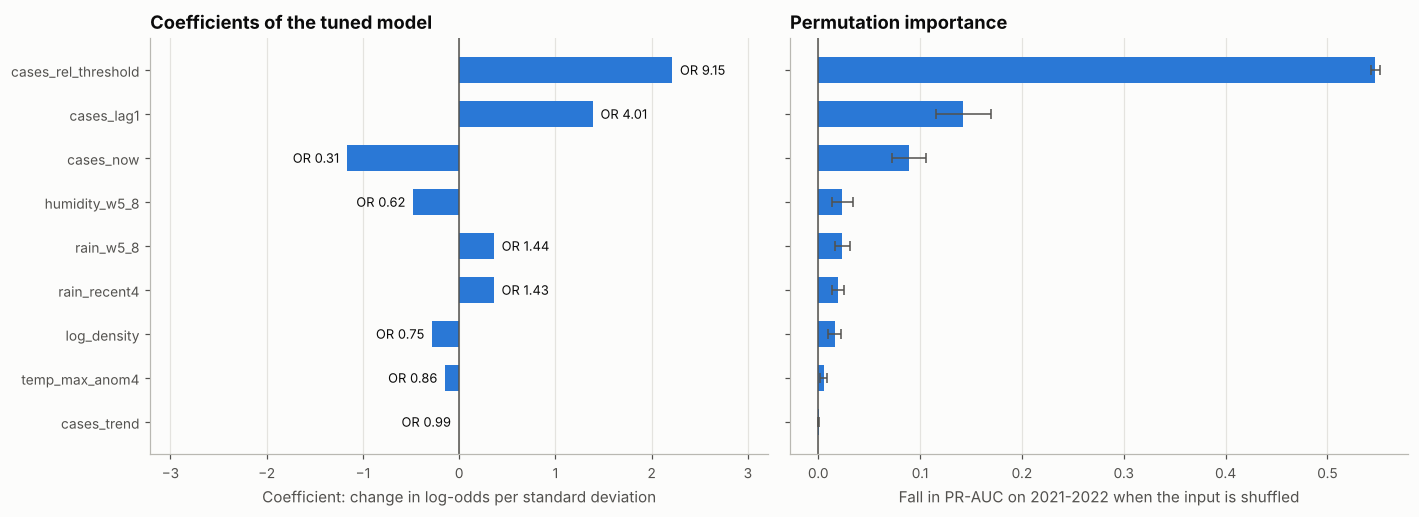

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
ordered = coefficients.sort_values("coefficient (log-odds per SD)", key=np.abs)

ax = axes[0]
ax.barh(ordered.index, ordered["coefficient (log-odds per SD)"], height=0.6, color=viz.BLUE)
for i, (value, ratio) in enumerate(zip(ordered["coefficient (log-odds per SD)"], ordered["odds ratio per SD"])):
    ax.annotate(f"OR {ratio:.2f}", (value, i), textcoords="offset points", xytext=(5 if value >= 0 else -5, 0),
                ha="left" if value >= 0 else "right", va="center", fontsize=8.5, color=viz.TEXT)
ax.axvline(0, color=viz.TEXT_MUTED, linewidth=1)
span = ordered["coefficient (log-odds per SD)"].abs().max()
ax.set_xlim(-span * 1.45, span * 1.45)
ax.set_xlabel("Coefficient: change in log-odds per standard deviation")
ax.set_title("Coefficients of the tuned model")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.barh(ordered.index, ordered["permutation: drop in PR-AUC"], height=0.6, color=viz.BLUE,
        xerr=ordered["permutation: std"], error_kw={"ecolor": viz.TEXT_MUTED, "elinewidth": 1, "capsize": 3})
ax.axvline(0, color=viz.TEXT_MUTED, linewidth=1)
ax.set_xlabel("Fall in PR-AUC on 2021-2022 when the input is shuffled")
ax.set_title("Permutation importance")
ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save(fig, "lr_04_coefficients")
plt.show()

**Finding.** The case inputs carry the model. `cases_rel_threshold` has the largest weight (odds ratio 9.2 per standard deviation) and the largest permutation importance (0.547), followed by last week's cases (odds ratio 4.0, importance 0.142).

This week's absolute count has a negative weight (odds ratio 0.31) even though shuffling it costs 0.090 of PR-AUC. This is the correlated-inputs effect described in section 1. With the relative level held fixed, a higher absolute count simply means a district with a higher threshold, usually a larger district, and the model gives such districts lower odds (×0.66 when the count doubles at the same relative level). Read together, the case weights behave as expected: when this week's cases double, the odds of an outbreak two weeks later roughly double (×1.96 on average), and when both this week's and last week's cases double they roughly triple (×3.18).

Recent rainfall and rainfall five to eight weeks earlier both raise the odds (odds ratios 1.43 and 1.44), in line with mosquito breeding after rain. Humidity five to eight weeks earlier has a negative weight once case history is accounted for (odds ratio 0.62). On its own humidity rises with cases (`01b_eda_features.ipynb`), so this should not be read as humidity protecting against dengue. Each of these three climate inputs moves PR-AUC by about 0.02. That is small, but more than in the Random Forest, where humidity was the only climate input above 0.01. The temperature anomaly and `cases_trend` add almost nothing.

## 8. Summary for the report

- **Tuned settings:** L2 penalty with C = 10 (any C from 0.01 to 10 scores the same), no class weighting. Decision threshold 0.24, chosen on the cross-validation predictions.
- **Cross-validation, 2016 to 2020:** PR-AUC 0.696, 0.009 above the persistence score (0.687), ahead in 2018 and 2020, level in 2019, behind in 2016 and 2017. Tuning added only 0.004; class weighting did not help.
- **Onsets and continuing outbreaks:** better than the persistence score on both (onsets 0.257 against 0.231; continuing 0.836 against 0.818), and it flags 18% of onsets at its threshold.
- **Validation, 2021 to 2022:** PR-AUC 0.585 against 0.554 for the persistence score, ahead in 86% of bootstrap resamples but not conclusively. It catches 45 of the 77 outbreaks (persistence 43) with 45 false alarms (34), and ranks onsets better (0.173 against 0.082).
- **What it learned:** the relative case level and last week's cases dominate; doubling this week's cases roughly doubles the odds of an outbreak two weeks later. Rainfall raises the odds; each climate input adds about 0.02 of PR-AUC.

**Points for the critical analysis**

- With far more training weeks than inputs, regularisation has little to do. The model's limit is its linear form, not overfitting.
- Compared with the Random Forest (`03_model_b_random_forest.ipynb`), Logistic Regression is lower in cross-validation (0.696 against 0.711) but higher on 2021 to 2022 (0.585 against 0.538), and better at onsets in both periods. The forest's gain comes mainly from judging whether an ongoing outbreak will continue. Step 11 compares the two on the test years.
- Correlated case inputs make individual weights misleading when read alone, as the negative weight on this week's count shows.

The tuned settings and threshold are saved to `results/metrics/lr_final_settings.json` for the final comparison in step 11.

In [17]:
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
tuning.to_csv(config.METRICS_DIR / "lr_tuning_results.csv", index=False)
by_year.to_csv(config.METRICS_DIR / "lr_cv_by_year.csv")
cv_metrics.to_csv(config.METRICS_DIR / "lr_cv_threshold_metrics.csv", index=False)
onsets.to_csv(config.METRICS_DIR / "lr_onsets.csv")
validation.to_csv(config.METRICS_DIR / "lr_validation_metrics.csv")
coefficients.to_csv(config.METRICS_DIR / "lr_coefficients.csv")

best_clf = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
final_settings = {
    "model": "Logistic Regression",
    "owner": "Member A",
    "preprocessing": "make_selected_preprocessor() (L1 selection, C = 0.01)",
    "hyperparameters": {"penalty": "L2 (scikit-learn default)", "max_iter": 5000, **best_clf},
    "decision_threshold": round(THRESHOLD, 6),
    "threshold_rule": "maximise F1 averaged across the 2016-2020 cross-validation years",
    "cv_mean_pr_auc_2016_2020": round(float(search.best_score_), 6),
    "validation_pr_auc_2021_2022": round(float(validation.loc["Logistic Regression, tuned", "PR-AUC"]), 6),
    "inputs_used": inputs,
    "trained_on": "train split, 2007-2020",
}
with open(config.METRICS_DIR / "lr_final_settings.json", "w") as f:
    json.dump(final_settings, f, indent=2, default=str)
print("Saved lr_* tables and lr_final_settings.json to results/metrics/")
final_settings

Saved lr_* tables and lr_final_settings.json to results/metrics/


{'model': 'Logistic Regression',
 'owner': 'Member A',
 'preprocessing': 'make_selected_preprocessor() (L1 selection, C = 0.01)',
 'hyperparameters': {'penalty': 'L2 (scikit-learn default)',
  'max_iter': 5000,
  'C': 10,
  'class_weight': None},
 'decision_threshold': 0.241774,
 'threshold_rule': 'maximise F1 averaged across the 2016-2020 cross-validation years',
 'cv_mean_pr_auc_2016_2020': 0.696272,
 'validation_pr_auc_2021_2022': 0.585119,
 'inputs_used': ['cases_now',
  'cases_lag1',
  'cases_rel_threshold',
  'rain_recent4',
  'rain_w5_8',
  'cases_trend',
  'humidity_w5_8',
  'temp_max_anom4',
  'log_density'],
 'trained_on': 'train split, 2007-2020'}